# Real-time carbon accounting and material transition for hydrogen systems

**Pure Pyomo + Gurobi re-implementation of `Texas TVEF Battery.ipynb`.**

This notebook solves exactly the same case study (same data files, same resources, processes, costs, emission
factors, battery, demand-penalty tiers, ramp/min-load/smoothing constraints and epsilon-constraint sweep) as the
energiapy version, but the MILP is written directly in Pyomo. No `energiapy` import is needed.

**Validation against the energiapy notebook:** the GWP-minimization objective (2,228,411.58 kg CO2-eq) is reproduced
exactly, and the cost-minimization model (without the smoothing block, as in the saved `res_cost.pkl`) reproduces the
installed SMR capacity (23,802.79 kg/hr) exactly and the objective within Gurobi's MIP-gap tolerance.

Output files of this notebook are prefixed with `Pyomo_` (and the epsilon-constraint pickles go to `res_red_pyomo/`)
so that the results of the energiapy notebook are not overwritten.

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Rahul Kakodkar", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.1.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"

## Problem Statement

The goal is to meet a fixed (daily varying) demand of hydrogen while optimizing the production process.
Several hydrogen pathways can be utilized (SMR, SMR + CCS, PEM, AWE, ATR + CCS variants), each with their respective
emissions, powered by grid electricity (with an hourly varying price and hourly varying emission factor, TVEF),
a solar PPA, a wind PPA and a lithium-ion battery.

Hypothesis: By using real-time carbon accounting, decisions and changes can be made in a more dynamic nature.

Users are advised caution in terms of assigning the emissions at the appropriate levels and avoiding double accounting.
The direct emissions are considered through the resource balance constraint (CO2 to stack / CO2 vented are "sold"
resources with a GWP of 1 kg CO2-eq per kg).

## Nomenclature

*Sets*

$\mathcal{R}$ - set of all resources r

$\mathcal{P}$ - set of all processes p

$\mathcal{T}$ - set of hourly temporal periods t (8760)

$\mathcal{D}$ - set of days d (365)

*Subsets*

$\mathcal{R}^{storage}$ - set of resources that can be stored (battery energy)

$\mathcal{R}^{sell}$ - set of resources that can be discharged

$\mathcal{R}^{demand}$ - set of resources that meet demand (pure hydrogen)

$\mathcal{R}^{cons}$ - set of resources that can be consumed (purchased)

$\mathcal{P}^{varying}$ - set of processes with time varying capacity (PV, WF)

*Continuous Variables*

$P_{p,t}$ - production level of p $\in$ $\mathcal{P}$ in time period t

$C_{r,t}$ - consumption of r $\in$ $\mathcal{R}^{cons}$ in time period t

$S_{r,t}$ - discharge of r $\in$ $\mathcal{R}^{sell}$ in time period t

$Inv_{r,t}$ - inventory level of r $\in$ $\mathcal{R}^{storage}$ in time period t

$Cap^S_{r}$ - installed inventory capacity for resource r $\in$ $\mathcal{R}^{storage}$

$Cap^P_{p}$ - installed production capacity for process p $\in$ $\mathcal{P}$

*Binary Variables*

$X^P_{p}$ - network binary for production process p $\in$ $\mathcal{P}$

$X^S_{r}$ - network binary for inventory of resource r $\in$ $\mathcal{R}^{storage}$

*Parameters*

$Cap^{P-max}_{p}$, $Cap^{P-min}_{p}$ - maximum / minimum production capacity of process p

$Cap^{S-max}_{r}$ - maximum inventory capacity for resource r

$Capex_{p}$, $Fopex_{p}$, $Vopex_{p}$ - capital / fixed / variable expenditure of process p

$Price_{r,t}$ - purchase price for resource r in time t

$C^{max}_{r}$ - maximum hourly consumption availability for resource r

$D_{d}$ - daily hydrogen demand

$\eta_{p,r}$ - conversion of resource r by process p (negative = consumed, positive = produced)

$\phi_{p,t}$ - capacity factor of process p in time t

$GWP_{r,t}$ - global warming indicator of resource r in time t (time varying for grid power)

## MILP Formulation

\begin{equation}
min \; \sum_{p \in \mathcal{P}} (Capex_{p} + Fopex_{p}) \, Cap^P_{p} + Capex^{S} \, Cap^S + \sum_{t \in \mathcal{T}} \sum_{p \in \mathcal{P}} Vopex_{p} \, P_{p,t} + \sum_{t \in \mathcal{T}} \sum_{r \in \mathcal{R}^{cons}} Price_{r,t} \, C_{r,t}
\end{equation}

\begin{equation}
Cap^P_{p} \leq Cap^{P-max}_{p} X^P_{p}, \quad Cap^P_{p} \geq Cap^{P-min}_{p} X^P_{p} \hspace{1cm} \forall p \in \mathcal{P}
\end{equation}

\begin{equation}
Cap^S_{r} \leq Cap^{S-max}_{r} X^S_{r} \hspace{1cm} \forall r \in \mathcal{R}^{storage}
\end{equation}

\begin{equation}
P_{p,t} \leq \phi_{p,t} \, Cap^{P}_{p} \hspace{1cm} \forall p \in \mathcal{P}, t \in \mathcal{T}
\end{equation}

\begin{equation}
Inv_{r,t} \leq Cap^{S}_{r} \hspace{1cm} \forall r \in \mathcal{R}^{storage}, t \in \mathcal{T}
\end{equation}

\begin{equation}
C_{r,t} \leq C^{max}_{r} \hspace{1cm} \forall r \in \mathcal{R}^{cons}, t \in \mathcal{T}
\end{equation}

\begin{equation}
C_{r,t} + \sum_{p \in \mathcal{P}} \eta_{p,r} P_{p,t} - S_{r,t} = Inv_{r,t} - Inv_{r,t-1} \hspace{1cm} \forall r \in \mathcal{R}, t \in \mathcal{T}
\end{equation}

\begin{equation}
\sum_{t \in d} S_{H_2,t} \; (=, \geq) \; D_{d} \hspace{1cm} \forall d \in \mathcal{D}
\end{equation}

\begin{equation}
GWP = \sum_{t \in \mathcal{T}} \Big( \sum_{r \in \mathcal{R}^{cons}} GWP_{r,t} \, C_{r,t} + \sum_{r \in \mathcal{R}^{sell}} GWP_{r} \, S_{r,t} \Big)
\end{equation}

\begin{equation}
S_{r,t}, C_{r,t}, Inv_{r,t}, P_{p,t}, Cap^P_{p}, Cap^S_{r} \in R_{\geq 0}, \quad X^P_{p}, X^S_{r} \in \{0,1\}
\end{equation}

Additional operational constraints (ramp rate, minimum load, second-difference smoothing) are applied to SMR,
ATR_CCS_R and ATR_CCS_R_OC exactly as in the energiapy notebook, and the epsilon-constraint method bounds GWP to a
percentage of the cost-optimal GWP.

## Import Modules

In [45]:
import os
import gc
import time
import pickle
from pathlib import Path
from itertools import product

import numpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyomo.environ import (ConcreteModel, Var, Constraint, Objective, Expression, Set, Param,
                           NonNegativeReals, Binary, minimize, quicksum, value, SolverFactory,
                           TerminationCondition)

## Data Import

Identical data files and preprocessing as the energiapy notebook.

In [46]:
BASE = 'C:/Users/marcopdsousa/Documents/energiapy'
horizon = 1

**Declare temporal scale**

energiapy used `TemporalScale(discretization_list=[1, 365, 24])`, i.e. one network period, 365 days and 24 hours.
Here the scheduling index is a flat hourly index `t = 0 ... 8759` with `day = t // 24` and `hour = t % 24`.
The tuple representation `(0, day, hour)` is kept for result dictionaries so that they match the energiapy output format.

In [47]:
N_DAYS = 365
N_HOURS = 24
N_T = N_DAYS * N_HOURS                     # 8760 scheduling periods
T = list(range(N_T))
DAYS = list(range(N_DAYS))
scale_iter = [(0, d, h) for d in DAYS for h in range(N_HOURS)]   # energiapy-style (network, day, hour) tuples
NETWORK_PERIOD = 0
LOCATION = 'BG'                            # location key kept identical to the energiapy notebook for result compatibility

## Declare resources

Resources can be consumed, produced, stored, discharged (or sold).

In [48]:
bigM = 10**8
smallM = 0.001

Hourly electricity prices

In [49]:
file_path = f'{BASE}/ChemSus Conference/Data for Model/Ercot Prices 2025.xlsx'

all_sheets = pd.read_excel(file_path, sheet_name=None)

df_list = []
for sheet_name, df in all_sheets.items():
    df['SheetName'] = sheet_name
    df_list.append(df)

elec_price_df = pd.concat(df_list, ignore_index=True)

elec_price_df = elec_price_df[elec_price_df['Settlement Point'] == 'HB_HUBAVG']
elec_price_df = elec_price_df[['Settlement Point Price']].reset_index(drop=True)
elec_price_df = elec_price_df.iloc[:8760]

elec_price_df

,Settlement Point Price
0,23.07
1,21.20
2,20.37
3,21.61
4,21.79
...,...
8755,33.92
8756,26.68
8757,22.62
8758,24.19


Hourly Natural Gas Prices

In [50]:
# The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
NG_price_df = pd.read_csv(f'{BASE}/AICHE/Historical natural gas prices/Natural gas historical data.csv')
NG_price_df = NG_price_df[['Henry Hub Natural Gas Spot Price (Dollars per Million Btu)']]
NG_price_hourly = NG_price_df.reindex(NG_price_df.index.repeat(30))
NG_price_hourly = NG_price_hourly[:8760]
NG_price_hourly = pd.DataFrame(NG_price_hourly)

mean = NG_price_hourly.mean()
std = NG_price_hourly.std()

outliers = numpy.abs(NG_price_hourly - mean) > 3 * std
# Prune outliers beyond 3 standard deviations
NG_price_hourly = NG_price_hourly.mask(outliers)
fill_value = NG_price_hourly.mean()
NG_price_hourly = NG_price_hourly.fillna(fill_value)
NG_price_hourly

,Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
0,2.39
0,2.39
0,2.39
0,2.39
0,2.39
...,...
291,4.63
291,4.63
291,4.63
291,4.63


In [51]:
Demand_df = pd.read_csv(f'{BASE}/ESCAPE/Belgium Data/Belgium_H2_Demand_2024.csv')
Demand_df = Demand_df[['Hydrogen_Demand_kg_per_day']]
Demand_df = Demand_df[:365].reset_index(drop=True)
Demand_df

,Hydrogen_Demand_kg_per_day
0,374133.83
1,361866.59
2,373656.88
3,355088.91
4,367889.56
...,...
360,370519.18
361,377831.44
362,357199.97
363,350742.39


In [52]:
GWP_df = pd.read_csv(f'{BASE}/ChemSus Conference/Data for Model/Ercot EI profile.csv')
GWP_df = GWP_df[['mean']]
GWP_df = GWP_df[:8760].reset_index(drop=True)
GWP_df

,mean
0,487.476900
1,484.815385
2,481.876923
3,486.061538
4,431.615385
...,...
8755,376.569231
8756,388.830769
8757,400.753846
8758,437.153846


In [53]:
GWP_df.max()

mean    545.301587
dtype: float64

In [54]:
# Gives relevancy to price values again (energiapy normalizes every factor by its maximum, so the base value is the maximum)
elec_price = elec_price_df.max().iloc[0]
NG_price = NG_price_df.max().iloc[0]
GWP_value = GWP_df.max().iloc[0]
print(f'elec_price (max) = {elec_price}, NG_price (max) = {NG_price}, GWP_value (max) = {GWP_value}')

elec_price (max) = 813.12, NG_price (max) = 23.86, GWP_value (max) = 545.3015873


Hourly Wind availability

In [55]:
Wind_df = pd.read_csv(f'{BASE}/ChemSus Conference/Data for Model/Final Wind Availability ERCOT 2025 Hourly.csv')
Wind_df = Wind_df[['Wind availability']]
Wind_df = Wind_df[:8760]
Wind_df

,Wind availability
0,12875.2
1,13409.5
2,14153.7
3,14785.8
4,14540.1
...,...
8754,9737.6
8755,12620.1
8756,15355.5
8757,17537.9


Hourly Solar availability

In [56]:
Solar_df = pd.read_csv(f'{BASE}/ChemSus Conference/Data for Model/Final Solar Availability ERCOT 2025 Hourly.csv')
Solar_df = Solar_df[['HSLSystemWide']]
Solar_df = Solar_df[:8760]
Solar_df

,HSLSystemWide
0,0.65
1,0.64
2,0.62
3,0.61
4,0.63
...,...
8755,0.66
8756,0.55
8757,0.54
8758,0.56


### Normalized factors

energiapy's `scale_changer` turns every DataFrame factor into `x / x.max()` (missing values become 0) and the
`Location`/`Scenario` then multiply the base value (price, gwp, capacity, demand) by that factor.
The same is done here explicitly, which yields the *effective* hourly parameters used in the model.

In [57]:
def normalized_factor(df, n):
    """energiapy scale_changer equivalent: pad/truncate to n periods, divide by the column maximum, NaN -> 0."""
    s = pd.Series(df.iloc[:, 0].to_numpy(dtype=float)).reindex(range(n))
    s = s / s.max(skipna=True)
    return s.fillna(0.0).to_numpy()

price_factor_grid = normalized_factor(elec_price_df, N_T)
price_factor_ng = normalized_factor(NG_price_hourly, N_T)
gwp_factor_grid = normalized_factor(GWP_df, N_T)
capacity_factor_pv = normalized_factor(Solar_df, N_T)
capacity_factor_wf = normalized_factor(Wind_df, N_T)      # the wind file has 8759 rows -> last hour factor is 0 (as in energiapy)
demand_factor_h2 = normalized_factor(Demand_df, N_DAYS)

# demand (not an uncertainty handle for now)
H2_DEMAND_BASE = 360000                                 # kg/day (Scenario demand={Belgium: {H2Pure: 360000}})
h2_demand = H2_DEMAND_BASE * demand_factor_h2           # kg/day, daily

# The effective hourly prices / emission factors (grid_price, ng_price, grid_gwp, capacity factors) are produced by
# `make_inputs` below, so that the uncertainty handles of the `params` table can scale or replace them.
pd.DataFrame({'price_factor_grid': price_factor_grid, 'price_factor_ng': price_factor_ng, 'gwp_factor_grid': gwp_factor_grid,
              'cf_pv': capacity_factor_pv, 'cf_wf': capacity_factor_wf}).describe()

,price_factor_grid,price_factor_ng,gwp_factor_grid,cf_pv,cf_wf
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,0.041196,0.451893,0.786800,0.276754,0.406850
std,0.033178,0.125158,0.079337,0.338794,0.219115
min,-0.002484,0.275701,0.564941,0.000000,0.000000
25%,0.026577,0.338493,0.729304,0.000031,0.220325
50%,0.034226,0.442757,0.785411,0.018451,0.387118
75%,0.046973,0.540012,0.846896,0.610175,0.570272
max,1.000000,1.000000,1.000000,1.000000,1.000000


### Resource declarations

Resource names are kept identical to the energiapy `Resource(name=...)` strings so that result dictionaries are
directly comparable. `cons_max > 0` marks a purchasable resource, `sell=True` a dischargeable resource.
`varying` mirrors the energiapy `VaryingResource` flags: a resource with an explicit `varying` list has no
consumption bound in energiapy (GridPower, Natural Gas) and its price/GWP is multiplied by the hourly factor.

`scope` assigns every emitting resource to an emission scope:
- scope 1: direct process emissions, i.e. CO2 to stack and CO2 vented (GWP of 1 kg CO2e per kg discharged),
- scope 2: purchased electricity (grid power with the time varying emission factor; PPA power is zero under the
  market-based convention and carries the grid factor under the location-based convention),
- scope 3: upstream emissions of purchased natural gas.

In [58]:
Solar = 'Solar'
Wind = 'Wind'
Power = 'Power'
GridPower = 'GridPower'
CO2_Stack = 'CO2 to Stack'
CO2_Air = 'CO2 from air'
CO2_Vent = 'CO2 Vented from the process'
CO2cpt = 'CO2 Captured'
NG = 'Natural Gas'
H2Pure = 'Pure Hydrogen'
H2OFresh = 'H2O Fresh'
H2O_Air = 'H2O from air'
H2O_Vent = 'H2O vented from the process'
H2O_Stack = 'H2O to Stack'
H2O_Vent_ASU = 'H2O Vent from ASU'
H2O_Blowdown = 'H2O in Blowdown'
N2_Air = 'N2 from Air'
N2_Vent = 'N2 vented from the process'
N2Prod = 'N2 in product stream'
N2_Stack = 'N2 to Stack'
N2_Desorped = 'N2 Desorped'
N2_Vented_Stack = 'N2 in Stack'
N2_Blowdown = 'N2 in Blowdown'
O2_Air = 'O2 from air'
O2_Vent = 'O2 vented from the process'
O2_Stack = 'O2 to Stack'
O2_Desorped = 'O2 Desorped'
O2_ASU = 'O2 vented out of ASU'
O2_Blowdown = 'O2 in Blowdown'
DP1, DP2, DP3, DP4 = 'DP1', 'DP2', 'DP3', 'DP4'


def resource(cons_max=0.0, price=0.0, gwp=0.0, sell=False, demand=False, varying=None, scope=None, basis='kg/hr', label=''):
    if demand:
        sell = True
    return dict(cons_max=cons_max, price=price, gwp=gwp, sell=sell, demand=demand,
                varying=varying, scope=scope, basis=basis, label=label)


resources = {
    Solar: resource(cons_max=bigM, price=52.69, gwp=0, scope=2, basis='MW', label='Solar Power'),      # 52.69 USD/MWh
    Wind: resource(cons_max=bigM, price=60.11, gwp=0, scope=2, basis='MW', label='Wind Power'),        # 60.11 USD/MWh
    Power: resource(basis='MW', label='Power generated'),
    GridPower: resource(cons_max=bigM, price=elec_price, gwp=GWP_value, varying=['price', 'gwp'], scope=2,
                        basis='MW', label='Power bought'),
    # components of natural gas / flue gas
    CO2_Stack: resource(sell=True, gwp=1, scope=1, label='Carbon dioxide to Stack'),
    CO2_Air: resource(cons_max=bigM, label='Carbon dioxide from air'),
    CO2_Vent: resource(sell=True, gwp=1, scope=1, label='Carbon dioxide vented from the process'),
    CO2cpt: resource(sell=True, label='Captured carbon dioxide'),
    NG: resource(cons_max=bigM, price=NG_price / 20, gwp=0.960979, varying=['price'], scope=3, label='Natural Gas'),
    # ^ upstream natural gas emissions (scope 3); the nominal 0.960979 kg CO2e/kg NG is the `ng_upstream_ef` handle
    # hydrogen demand
    H2Pure: resource(demand=True, varying=['demand'], label='Pure Hydrogen'),
    # water (industrial water price is 0.002 USD/kg)
    H2OFresh: resource(cons_max=bigM, price=0.002, label='Fresh Water'),
    H2O_Air: resource(cons_max=bigM, label='Water from air'),
    H2O_Vent: resource(sell=True, label='Water vented from the process'),
    H2O_Stack: resource(sell=True, label='Water to Stack'),
    H2O_Vent_ASU: resource(sell=True, label='Water vented from ASU'),
    H2O_Blowdown: resource(sell=True, label='H2O present in air - Stream 5'),
    # air components
    N2_Air: resource(cons_max=bigM, label='Nitrogen from Air'),
    N2_Vent: resource(sell=True, label='Nitrogen vented from the process'),
    N2Prod: resource(sell=True, label='Nitrogen in product stream'),
    N2_Stack: resource(sell=True, label='Nitrogen to stack'),
    N2_Desorped: resource(sell=True, label='Nitrogen in CO2 desorption stream'),
    N2_Vented_Stack: resource(sell=True, label='Nitrogen in Stack'),
    N2_Blowdown: resource(sell=True, label='Nitrogen in Blowdown stream'),
    O2_Air: resource(cons_max=bigM, label='Oxygen from air'),
    O2_Vent: resource(sell=True, label='Oxygen vented from the process'),
    O2_Stack: resource(sell=True, label='Oxygen to Stack'),
    O2_Desorped: resource(sell=True, label='Oxygen in CO2 desorption stream'),
    O2_ASU: resource(sell=True, label='O2 vented out of ASU'),
    O2_Blowdown: resource(sell=True, label='O2 in Blowdown stream'),
    # demand penalty tiers (purchasable "deficit" hydrogen at increasing penalty prices)
    DP1: resource(cons_max=750, price=10, label='DP1'),     # 5% deviation
    DP2: resource(cons_max=2250, price=25, label='DP2'),    # 15% deviation
    DP3: resource(cons_max=4000, price=50, label='DP3'),    # 27% deviation
    DP4: resource(cons_max=5250, price=115, label='DP4'),
}

## Declare Processes

Conversion dictionaries, capex/vopex/fopex and capacity bounds are identical to the energiapy notebook.
`capacity_factor` marks processes with a deterministic time varying capacity (PV, WF).

In [59]:
def process(conversion, capex=0.0, vopex=0.0, fopex=0.0, prod_min=0.0, prod_max=0.0, capacity_factor=None, basis='kg/hr', label=''):
    return dict(conversion=conversion, capex=capex, vopex=vopex, fopex=fopex, prod_min=prod_min, prod_max=prod_max,
                capacity_factor=capacity_factor, basis=basis, label=label)


processes = {
    # Purchasing electricity from a traditional power production system
    'Grid': process({GridPower: -1, Power: 1}, prod_min=bigM, prod_max=bigM, basis='MW', label='Grid'),

    'PV': process({Solar: -1, Power: 0.22}, prod_max=600, prod_min=600, capacity_factor=capacity_factor_pv,
                  basis='MW', label='Solar PV'),

    'WF': process({Wind: -1, Power: 0.4}, prod_max=650, prod_min=650, capacity_factor=capacity_factor_wf,
                  basis='MW', label='Wind mill array'),

    'SMR': process({Power: -0.00065, NG: -3.535189, H2OFresh: -16.78877421, N2_Air: -19.2134, O2_Air: -5.88716,
                    H2O_Air: -0.1582, CO2_Air: -0.01171,
                    H2Pure: 1, CO2_Stack: 9.3713, H2O_Stack: 3.94959, N2_Stack: 19.29814, O2_Stack: 0.535434},
                   capex=0.2, vopex=0.38, fopex=0.06, prod_min=smallM, prod_max=bigM, label='SMR'),

    'SMRCCS': process({Power: -0.00139, N2_Air: -22.2315, O2_Air: -6.811924, H2O_Air: -0.183055, CO2_Air: -0.013551,
                       CO2_Stack: -9.3713,
                       H2O_Vent: 3.826767, CO2cpt: 8.903, CO2_Vent: 0.46856, H2O_Stack: 0.558114, N2_Stack: 22.32218,
                       O2_Stack: 0.6203032},
                      capex=0.45, vopex=1.01, fopex=0.1, prod_min=smallM, prod_max=bigM, label='SMRCCS'),

    'PEM': process({Power: -0.052, H2OFresh: -9.5, H2Pure: 1},
                   capex=1.5, vopex=3.43, fopex=0.7, prod_min=smallM, prod_max=bigM, label='PEM'),

    'ATR_CCS_R': process({Power: -0.0025838509316770185, NG: -3.2080287, H2OFresh: -4.8123228, H2O_Air: -0.1041653,
                          H2O_Vent_ASU: 0.0019387, H2O_Blowdown: 1.7351222, H2O_Vent: 0.5220523,
                          N2_Air: -12.653394, N2_Vent: 9.970844643, N2Prod: 0.002780318, N2_Vented_Stack: 2.182324573,
                          N2_Desorped: 0.023329689, O2_Air: -3.87607534,
                          O2_ASU: 0.061984387, O2_Vent: 0.0647028, CO2_Vent: 0.44956544299999995, CO2cpt: 7.733322317,
                          H2Pure: 1},
                         capex=0.35, vopex=0.74, fopex=0.08, prod_min=smallM, prod_max=bigM, label='ATR_CCS_R'),

    'ATR_CCS_R_OC': process({Power: -0.002881987577, NG: -3.208028688, CO2_Vent: 0.663744554, CO2cpt: 8.152141983,
                             N2_Air: -12.56295099, N2_Vent: 11.88406435, N2_Blowdown: 0.008434949, N2_Desorped: 0.102417105,
                             N2Prod: 0.002780318,
                             H2OFresh: -4.812322829, H2O_Air: -0.103420802, H2O_Vent_ASU: 0.002310721,
                             H2O_Blowdown: 0.004504513, O2_Air: -4.804359335,
                             O2_Vent: 0.073878039, H2Pure: 1},
                            capex=0.35, vopex=0.75, fopex=0.1, prod_min=smallM, prod_max=bigM, label='ATR_CCS_R_OC'),

    'AWE': process({Power: -0.06, H2OFresh: -9.4635, H2Pure: 1},
                   capex=0.810127, vopex=3.850633, fopex=0.202532, prod_min=smallM, prod_max=bigM, label='AWE'),

    # demand penalty "processes": convert the purchased deficit tiers into pure hydrogen at zero cost
    'D1': process({DP1: -1, H2Pure: 1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D1'),
    'D2': process({DP2: -1, H2Pure: 1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D2'),
    'D3': process({DP3: -1, H2Pure: 1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D3'),
    'D4': process({DP4: -1, H2Pure: 1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D4'),
}

### Lithium-ion battery

energiapy expands `Process(name='LiI', storage=Power, ...)` into
- a dummy stored resource `LiI_Power_stored` (with `store_max`),
- a charging process `LiI` : {Power: -1, LiI_Power_stored: +1} (vopex applies to charging),
- a discharging process `LiI_discharge` : {LiI_Power_stored: -1, Power: 1 - storage_loss} (no opex),
- storage capex applied to the installed storage capacity `Cap_S`.

The same expansion is done here explicitly.

In [60]:
battery = dict(name='LiI', storage=Power, vopex=0.5, capex=0.0, fopex=0.0, prod_min=0, prod_max=25,
               store_max=200, store_min=0, storage_loss=0.05, storage_capex=1250, storage_cost=0.0, basis='MW')

LiI_stored = f"{battery['name']}_{battery['storage']}_stored"          # 'LiI_Power_stored'

resources[LiI_stored] = resource(basis='MW', label='Power LiI(stored)')
resources[LiI_stored].update(store_max=battery['store_max'], store_min=battery['store_min'])

processes[battery['name']] = process({battery['storage']: -1, LiI_stored: 1},
                                     capex=battery['capex'], vopex=battery['vopex'], fopex=battery['fopex'],
                                     prod_min=battery['prod_min'], prod_max=battery['prod_max'],
                                     basis='MW', label='Lithium-ion battery')
processes[battery['name'] + '_discharge'] = process({LiI_stored: -1, battery['storage']: 1 * (1 - battery['storage_loss'])},
                                                    capex=battery['capex'], vopex=0, fopex=0,
                                                    prod_min=battery['prod_min'], prod_max=battery['prod_max'],
                                                    basis='MW', label='Lithium-ion battery_storage')

storage_capex = {LiI_stored: battery['storage_capex']}
storage_cost = {LiI_stored: battery['storage_cost']}

## Uncertainty handles: the `params` table

Every uncertain quantity enters the model through one of the handles below. A time series is never treated as 8760
independent unknowns: its uncertainty is a *level* multiplier (and, for the grid emission factor, the choice of the
percentile profile). The constant handles act on the conversion coefficients of the reforming/CCS processes or on
the upstream natural gas factor, and `scope2_convention` switches the scope 2 accounting convention.

| column | meaning |
|---|---|
| `nominal` | value used when nothing is overridden (reproduces the energiapy case study exactly) |
| `low`, `high` | screening range (literature based; update the provenance in `source` when you change them) |
| `type` | aleatory (natural variability), epistemic (lack of knowledge), choice (accounting convention) |
| `stage` | here-and-now (fixed before operation, drives design) or wait-and-see (revealed during the year) |

Use `make_inputs({'gas_price_level': 1.5, 'capture_rate_factor': 0.8})` to get the effective model inputs for any
combination of handle values, and `build_model(..., overrides={...})` to build the corresponding model.

In [61]:
params = pd.DataFrame([
    # handle                nominal     low        high        type         stage           unit              description                                                                                                   source
    ('gas_price_level',     1.0,        0.5,       1.5,        'aleatory',  'wait-and-see', '-',              'multiplier on the hourly natural gas price series (Henry Hub level)',                                        'Henry Hub 2021-2024 spanned ~2-9 USD/MMBtu'),
    ('elec_price_level',    1.0,        0.7,       1.3,        'aleatory',  'wait-and-see', '-',              'multiplier on the hourly ERCOT electricity price series (PPA prices unchanged)',                              'ERCOT year-to-year hub price variability'),
    ('grid_ef_profile',     'mean',     '0.1',     '0.9',      'aleatory',  'wait-and-see', 'column',         'column of "Ercot EI profile.csv" used as hourly grid emission factor: 0.1, 0.25, median, mean, 0.75, 0.9',   'rolling +/-3 day window quantiles of ERCOT 2017-2025 carbon intensity'),
    ('grid_ef_level',       1.0,        0.85,      1.15,       'aleatory',  'wait-and-see', '-',              'multiplier on the hourly grid emission factor',                                                              'interannual change of ERCOT average carbon intensity'),
    ('renewable_level',     1.0,        0.9,       1.1,        'aleatory',  'wait-and-see', '-',              'multiplier on the PV and wind capacity factors (capped at 1)',                                               'interannual resource variability'),
    ('ng_upstream_ef',      0.960979,   0.6,       2.5,        'epistemic', 'here-and-now', 'kg CO2e/kg NG',  'upstream (scope 3) emission factor of natural gas',                                                          '1-3 % methane leakage, GWP100 (29.8) vs GWP20 (82.5), AR6'),
    ('reformer_co2_yield',  9.3713,     8.9,       10.3,       'epistemic', 'here-and-now', 'kg CO2/kg H2',   'CO2 generated per kg H2 by SMR; CO2 generated by the ATR routes is scaled by the same relative factor',       'gas composition / heating value and reformer efficiency, ~ +/-5 %'),
    ('capture_rate_factor', 1.0,        0.70,      1.0,        'epistemic', 'here-and-now', '-',              'multiplier on the design capture rate of SMRCCS (0.950), ATR_CCS_R (0.945) and ATR_CCS_R_OC (0.925)',        'realized capture rates of operating CCS plants vs design'),
    ('scope2_convention',   'market',   'market',  'location', 'choice',    'here-and-now', '-',              'market-based: PPA power carries zero scope 2; location-based: PPA power carries the grid emission factor',   'GHG Protocol Scope 2 guidance'),
], columns=['handle', 'nominal', 'low', 'high', 'type', 'stage', 'unit', 'description', 'source']).set_index('handle')

pd.set_option('display.max_colwidth', 110)
params

,nominal,low,high,type,stage,unit,description,source
handle,,,,,,,,
gas_price_level,1.0,0.5,1.5,aleatory,wait-and-see,-,multiplier on the hourly natural gas price series (Henry Hub level),Henry Hub 2021-2024 spanned ~2-9 USD/MMBtu
elec_price_level,1.0,0.7,1.3,aleatory,wait-and-see,-,multiplier on the hourly ERCOT electricity price series (PPA prices unchanged),ERCOT year-to-year hub price variability
grid_ef_profile,mean,0.1,0.9,aleatory,wait-and-see,column,"column of ""Ercot EI profile.csv"" used as hourly grid emission factor: 0.1, 0.25, median, mean, 0.75, 0.9",rolling +/-3 day window quantiles of ERCOT 2017-2025 carbon intensity
grid_ef_level,1.0,0.85,1.15,aleatory,wait-and-see,-,multiplier on the hourly grid emission factor,interannual change of ERCOT average carbon intensity
renewable_level,1.0,0.9,1.1,aleatory,wait-and-see,-,multiplier on the PV and wind capacity factors (capped at 1),interannual resource variability
ng_upstream_ef,0.960979,0.6,2.5,epistemic,here-and-now,kg CO2e/kg NG,upstream (scope 3) emission factor of natural gas,"1-3 % methane leakage, GWP100 (29.8) vs GWP20 (82.5), AR6"
reformer_co2_yield,9.3713,8.9,10.3,epistemic,here-and-now,kg CO2/kg H2,CO2 generated per kg H2 by SMR; CO2 generated by the ATR routes is scaled by the same relative factor,"gas composition / heating value and reformer efficiency, ~ +/-5 %"
capture_rate_factor,1.0,0.7,1.0,epistemic,here-and-now,-,"multiplier on the design capture rate of SMRCCS (0.950), ATR_CCS_R (0.945) and ATR_CCS_R_OC (0.925)",realized capture rates of operating CCS plants vs design
scope2_convention,market,market,location,choice,here-and-now,-,market-based: PPA power carries zero scope 2; location-based: PPA power carries the grid emission factor,GHG Protocol Scope 2 guidance


### From handle values to model inputs

`make_inputs` returns everything `build_model` needs: the resource and process dictionaries (with the conversion
coefficients adjusted for the reformer CO2 yield and the capture rate), the effective hourly price / emission-factor
profiles, the capacity factors, and the scope assignment of every resource.

In [62]:
import copy

EI_PROFILE_PATH = f'{BASE}/ChemSus Conference/Data for Model/Ercot EI profile.csv'
EI_df = pd.read_csv(EI_PROFILE_PATH)
EI_df.columns = [str(c) for c in EI_df.columns]
GRID_EF_PROFILES = ['0.1', '0.25', 'median', 'mean', '0.75', '0.9']

# nominal CO2 split of the CCS processes: (captured, vented) per kg H2 -> design capture rate = cpt / (cpt + vent)
CCS_NOMINAL = {
    'SMRCCS':       dict(cpt=8.903,        vent=0.46856,             consumes_stack=True),
    'ATR_CCS_R':    dict(cpt=7.733322317,  vent=0.44956544299999995, consumes_stack=False),
    'ATR_CCS_R_OC': dict(cpt=8.152141983,  vent=0.663744554,         consumes_stack=False),
}
REFORMER_CO2_YIELD_NOMINAL = 9.3713          # SMR CO2 to stack per kg H2 (nominal value of the `reformer_co2_yield` handle)


def handle_values(overrides=None):
    """Nominal handle values updated with `overrides` (dict handle -> value). Unknown handles raise."""
    p = params['nominal'].to_dict()
    if overrides:
        unknown = set(overrides) - set(p)
        if unknown:
            raise KeyError(f'unknown uncertainty handle(s): {sorted(unknown)}; known handles: {list(p)}')
        p.update(overrides)
    return p


def make_inputs(overrides=None):
    """Effective model inputs for a set of handle values.

    Returns a dict with: p (handle values), resources, processes, price_profile (resource -> hourly array),
    gwp_profile (resource -> hourly array), capacity_factor (process -> hourly array), scope (resource -> 1/2/3/None).
    """
    p = handle_values(overrides)

    # ---------------- time series ----------------
    col = str(p['grid_ef_profile'])
    if col not in GRID_EF_PROFILES:
        raise ValueError(f"grid_ef_profile must be one of {GRID_EF_PROFILES}, got {col!r}")
    gwp_series = EI_df[[col]].iloc[:N_T].reset_index(drop=True)
    gwp_base = gwp_series.max().iloc[0]                                      # energiapy base value = maximum of the profile
    grid_gwp = p['grid_ef_level'] * gwp_base * normalized_factor(gwp_series, N_T)    # kg CO2e/MWh, hourly (TVEF)
    grid_price = p['elec_price_level'] * elec_price * price_factor_grid             # USD/MWh, hourly
    ng_price = p['gas_price_level'] * (NG_price / 20) * price_factor_ng             # USD/kg, hourly (NG_price/20 is the energiapy base price)
    cf_pv = np.minimum(1.0, p['renewable_level'] * capacity_factor_pv)
    cf_wf = np.minimum(1.0, p['renewable_level'] * capacity_factor_wf)

    # ---------------- resources ----------------
    res = copy.deepcopy(resources)
    res[NG]['gwp'] = float(p['ng_upstream_ef'])

    price_profile = {GridPower: grid_price, NG: ng_price}
    gwp_profile = {GridPower: grid_gwp}
    if p['scope2_convention'] == 'location':
        gwp_profile[Solar] = grid_gwp          # location-based: PPA power carries the grid factor of the hour
        gwp_profile[Wind] = grid_gwp
    elif p['scope2_convention'] != 'market':
        raise ValueError("scope2_convention must be 'market' or 'location'")

    # ---------------- processes ----------------
    pr = copy.deepcopy(processes)
    y = float(p['reformer_co2_yield'])
    rel = y / REFORMER_CO2_YIELD_NOMINAL
    pr['SMR']['conversion'][CO2_Stack] = y
    for name, d in CCS_NOMINAL.items():
        total = (d['cpt'] + d['vent']) * rel                                  # CO2 handled by the capture unit per kg H2
        rate = min(1.0, float(p['capture_rate_factor']) * d['cpt'] / (d['cpt'] + d['vent']))   # realized capture rate
        pr[name]['conversion'][CO2cpt] = rate * total
        pr[name]['conversion'][CO2_Vent] = (1 - rate) * total
        if d['consumes_stack']:
            pr[name]['conversion'][CO2_Stack] = -y                            # SMRCCS treats the CO2 of the SMR stack
    pr['PV']['capacity_factor'] = cf_pv
    pr['WF']['capacity_factor'] = cf_wf

    scope = {r: res[r]['scope'] for r in res}
    return dict(p=p, resources=res, processes=pr, price_profile=price_profile, gwp_profile=gwp_profile,
                capacity_factor={'PV': cf_pv, 'WF': cf_wf}, scope=scope,
                grid_price=grid_price, ng_price=ng_price, grid_gwp=grid_gwp)


nominal = make_inputs()
grid_price, ng_price, grid_gwp = nominal['grid_price'], nominal['ng_price'], nominal['grid_gwp']
pd.DataFrame({'grid_price': grid_price, 'ng_price': ng_price, 'grid_gwp': grid_gwp}).describe()

,grid_price,ng_price,grid_gwp
count,8760.000000,8760.000000,8760.000000
mean,33.497153,0.539109,429.043404
std,26.977866,0.149314,43.262497
min,-2.020000,0.328911,308.063492
25%,21.610000,0.403822,397.690476
50%,27.830000,0.528209,428.285714
75%,38.195000,0.644234,461.813492
max,813.120000,1.193000,545.301587


In [63]:
# sanity check: the nominal inputs reproduce the original conversion coefficients exactly
for name in ['SMR'] + list(CCS_NOMINAL):
    for r in (CO2_Stack, CO2cpt, CO2_Vent):
        a = processes[name]['conversion'].get(r, 0.0)
        b = nominal['processes'][name]['conversion'].get(r, 0.0)
        assert abs(a - b) < 1e-9, (name, r, a, b)
print('nominal conversion coefficients reproduced; design capture rates:',
      {k: round(d['cpt'] / (d['cpt'] + d['vent']), 4) for k, d in CCS_NOMINAL.items()})

nominal conversion coefficients reproduced; design capture rates: {'SMRCCS': 0.95, 'ATR_CCS_R': 0.9451, 'ATR_CCS_R_OC': 0.9247}


## Sets derived from the declarations (energiapy `Scenario.set_dict` equivalent)

The sets do not depend on the handle values (only coefficients change), so they are derived once from the nominal
declarations.

In [64]:
PROCS = sorted(processes.keys())
RES = sorted({r for p in PROCS for r in processes[p]['conversion']})           # only resources that appear in a conversion

R_PURCH = [r for r in RES if resources[r]['cons_max'] > 0]
R_SELL = [r for r in RES if resources[r]['sell']]
R_STORE = [r for r in RES if resources[r].get('store_max', 0) > 0]
R_DEMAND = [r for r in RES if resources[r]['demand']]

R_CERTAIN_AVAILABILITY = [r for r in R_PURCH if resources[r]['varying'] is None]
P_VARYING_CAPACITY = [p for p in PROCS if processes[p]['capacity_factor'] is not None]
SCOPES = [1, 2, 3]

print(f'{len(PROCS)} processes, {len(RES)} resources, {len(R_PURCH)} purchasable, {len(R_SELL)} dischargeable, {len(R_STORE)} storable')
print('purchasable :', R_PURCH)
print('dischargeable:', R_SELL)
print('storable     :', R_STORE)
print('scope of emitting resources:', {r: resources[r]['scope'] for r in RES if resources[r]['gwp'] != 0 or r in (Solar, Wind)})

15 processes, 32 resources, 13 purchasable, 17 dischargeable, 1 storable
purchasable : ['CO2 from air', 'DP1', 'DP2', 'DP3', 'DP4', 'GridPower', 'H2O Fresh', 'H2O from air', 'N2 from Air', 'Natural Gas', 'O2 from air', 'Solar', 'Wind']
dischargeable: ['CO2 Captured', 'CO2 Vented from the process', 'CO2 to Stack', 'H2O Vent from ASU', 'H2O in Blowdown', 'H2O to Stack', 'H2O vented from the process', 'N2 Desorped', 'N2 in Blowdown', 'N2 in Stack', 'N2 in product stream', 'N2 to Stack', 'N2 vented from the process', 'O2 to Stack', 'O2 vented from the process', 'O2 vented out of ASU', 'Pure Hydrogen']
storable     : ['LiI_Power_stored']
scope of emitting resources: {'CO2 Vented from the process': 1, 'CO2 to Stack': 1, 'GridPower': 2, 'Natural Gas': 3, 'Solar': 2, 'Wind': 2}


## Plot the time varying parameters

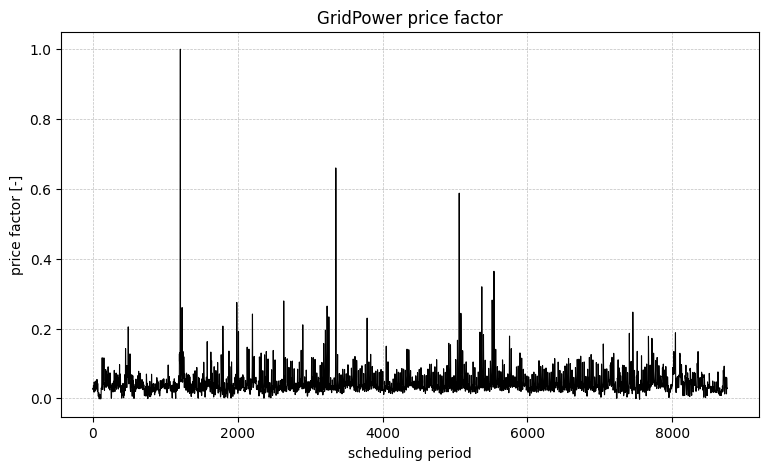

In [65]:
def plot_series(y, ylabel, color, title=None, fig_size=(9, 5)):
    fig, ax = plt.subplots(figsize=fig_size)
    ax.plot(range(len(y)), y, color=color, linewidth=0.8)
    ax.set_xlabel('scheduling period')
    ax.set_ylabel(ylabel)
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
    if title:
        ax.set_title(title)
    plt.show()

plot_series(price_factor_grid, 'price factor [-]', 'black', 'GridPower price factor')

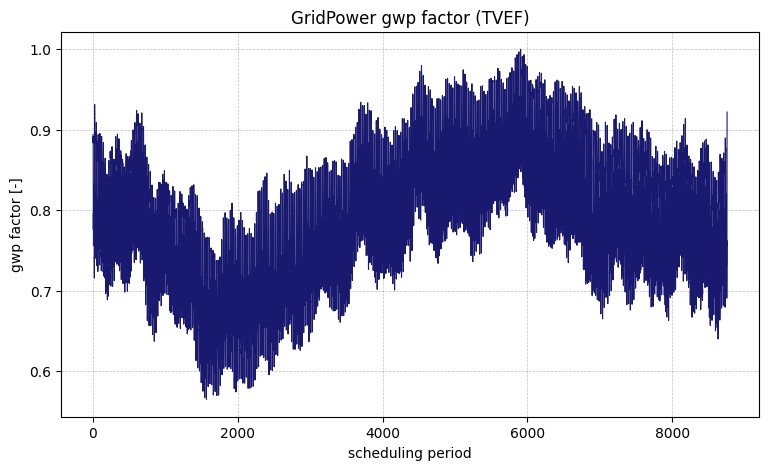

In [66]:
plot_series(gwp_factor_grid, 'gwp factor [-]', 'midnightblue', 'GridPower gwp factor (TVEF)')

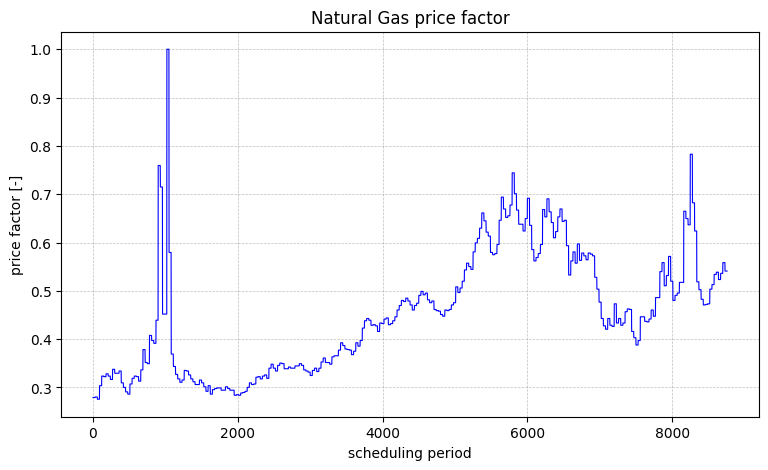

In [67]:
plot_series(price_factor_ng, 'price factor [-]', 'blue', 'Natural Gas price factor')

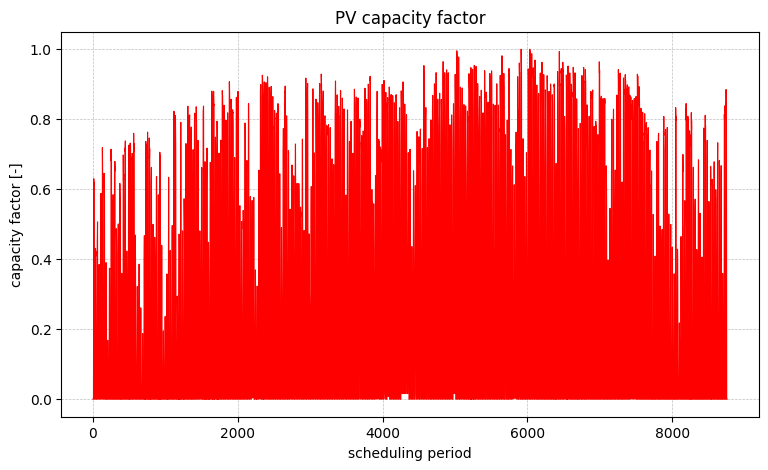

In [68]:
plot_series(capacity_factor_pv, 'capacity factor [-]', 'red', 'PV capacity factor')

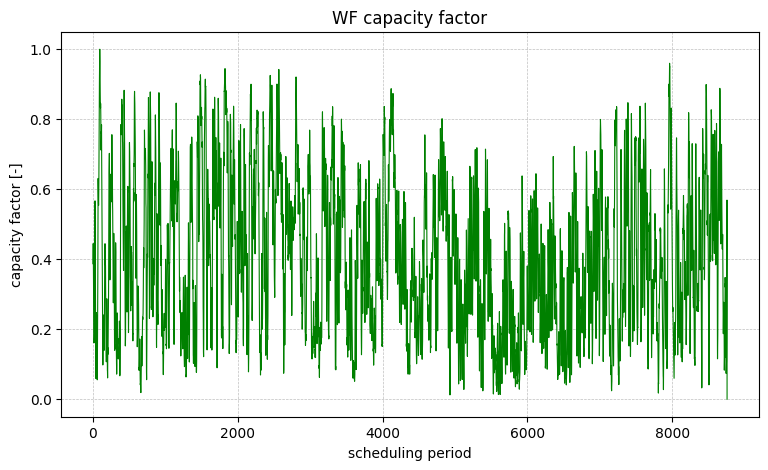

In [69]:
plot_series(capacity_factor_wf, 'capacity factor [-]', 'green', 'WF capacity factor')

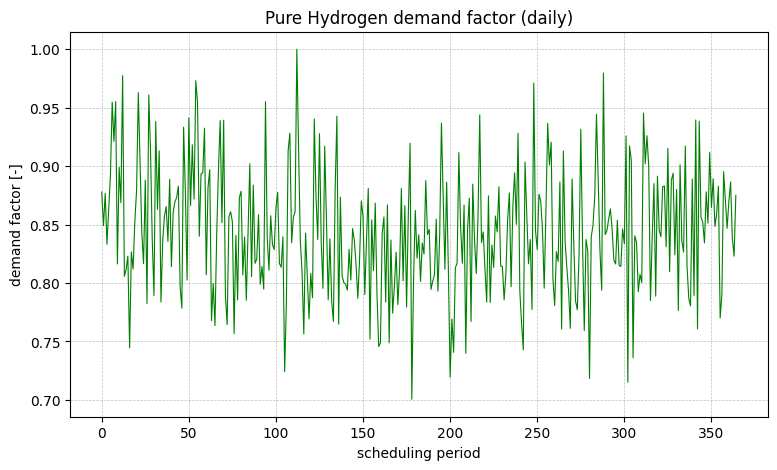

In [70]:
plot_series(demand_factor_h2, 'demand factor [-]', 'green', 'Pure Hydrogen demand factor (daily)')

## Formulate MILP (pure Pyomo)

`build_model` reproduces the energiapy constraint set used in the original notebook:
`COST, INVENTORY, NETWORK, PRODUCTION, RESOURCE_BALANCE, DEMAND, EMISSION` with either the `COST` or `MIN_GWP` objective.
It takes its coefficients from `make_inputs(overrides)`, i.e. from the handle values of the `params` table.

Variables (energiapy names): `P`, `C`, `S`, `Inv`, `Cap_P`, `Cap_S`, `X_P`, `X_S`.
Cost, GWP per resource, GWP per scope (`gwp_scope[1|2|3]`) and total GWP are Pyomo `Expression`s so that they can be
evaluated after the solve and used in constraints (e.g. scope-specific reduction targets or robust counterparts).

In [71]:
def build_model(objective='cost', demand_sign='eq', overrides=None, inputs=None, annualization_factor=1.0):
    """Builds the single-location design + scheduling MILP.

    objective   : 'cost' (minimize total annual cost) or 'gwp' (minimize total global warming potential)
    demand_sign : 'eq', 'geq' or 'leq' - how the daily hydrogen discharge relates to the daily demand
    overrides   : dict handle -> value for the uncertainty handles of the `params` table (nominal if None)
    inputs      : optionally a ready-made result of `make_inputs` (takes precedence over `overrides`)
    """
    if inputs is None:
        inputs = make_inputs(overrides)
    res = inputs['resources']
    pr = inputs['processes']
    price_profile = inputs['price_profile']
    gwp_profile = inputs['gwp_profile']
    scope_of = inputs['scope']
    R_VARYING_PRICE = [r for r in R_PURCH if r in price_profile]
    R_VARYING_GWP = [r for r in R_PURCH if r in gwp_profile]

    # conversion matrix (process -> resource -> coefficient) and reverse map (resource -> [(process, coefficient)])
    conversion = {p: {r: pr[p]['conversion'].get(r, 0.0) for r in RES} for p in PROCS}
    producers = {r: [(p, conversion[p][r]) for p in PROCS if conversion[p][r] != 0] for r in RES}

    m = ConcreteModel(name='Texas_TVEF_Battery')
    m.inputs = inputs                      # keep the realized handle values with the model (plain python attribute)

    # ---------------- sets ----------------
    m.T = Set(initialize=T, ordered=True)
    m.D = Set(initialize=DAYS, ordered=True)
    m.processes = Set(initialize=PROCS, ordered=True)
    m.resources = Set(initialize=RES, ordered=True)
    m.resources_purch = Set(initialize=R_PURCH, ordered=True)
    m.resources_sell = Set(initialize=R_SELL, ordered=True)
    m.resources_store = Set(initialize=R_STORE, ordered=True)

    # ---------------- variables ----------------
    def c_bounds(m, r, t):
        # energiapy only bounds consumption for resources with "certain availability" (no explicit varying list)
        return (0, res[r]['cons_max']) if r in R_CERTAIN_AVAILABILITY else (0, None)

    m.P = Var(m.processes, m.T, within=NonNegativeReals, doc='Production')
    m.C = Var(m.resources_purch, m.T, within=NonNegativeReals, bounds=c_bounds, doc='Resource consumption')
    m.S = Var(m.resources_sell, m.T, within=NonNegativeReals, doc='Resource discharged / sold')
    m.Inv = Var(m.resources_store, m.T, within=NonNegativeReals, doc='Resource inventory')
    m.Cap_P = Var(m.processes, within=NonNegativeReals, doc='Process capacity')
    m.Cap_S = Var(m.resources_store, within=NonNegativeReals, doc='Storage capacity')
    m.X_P = Var(m.processes, within=Binary, doc='Process network binary')
    m.X_S = Var(m.resources_store, within=Binary, doc='Storage network binary')

    # ---------------- network (facility sizing) ----------------
    m.constraint_production_facility = Constraint(
        m.processes, rule=lambda m, p: m.Cap_P[p] <= pr[p]['prod_max'] * m.X_P[p],
        doc='Cap_P <= prod_max * X_P')
    m.constraint_min_production_facility = Constraint(
        m.processes, rule=lambda m, p: m.Cap_P[p] >= pr[p]['prod_min'] * m.X_P[p],
        doc='Cap_P >= prod_min * X_P')
    m.constraint_production_max = Constraint(
        m.processes, rule=lambda m, p: m.Cap_P[p] <= pr[p]['prod_max'],
        doc='Cap_P <= prod_max')
    m.constraint_storage_facility = Constraint(
        m.resources_store, rule=lambda m, r: m.Cap_S[r] <= res[r]['store_max'] * m.X_S[r],
        doc='Cap_S <= store_max * X_S')
    m.constraint_min_storage_facility = Constraint(
        m.resources_store, rule=lambda m, r: m.Cap_S[r] >= res[r]['store_min'] * m.X_S[r],
        doc='Cap_S >= store_min * X_S')
    m.constraint_storage_max = Constraint(
        m.resources_store, rule=lambda m, r: m.Cap_S[r] <= res[r]['store_max'],
        doc='Cap_S <= store_max')

    # ---------------- production (nameplate capacity) ----------------
    def nameplate_production_rule(m, p, t):
        cf = pr[p]['capacity_factor']
        if cf is None:
            return m.P[p, t] <= m.Cap_P[p]
        return m.P[p, t] <= float(cf[t]) * m.Cap_P[p]
    m.constraint_nameplate_production = Constraint(m.processes, m.T, rule=nameplate_production_rule,
                                                   doc='P <= capacity_factor * Cap_P')

    # ---------------- inventory ----------------
    m.constraint_nameplate_inventory = Constraint(m.resources_store, m.T, rule=lambda m, r, t: m.Inv[r, t] <= m.Cap_S[r],
                                                  doc='Inv <= Cap_S')

    # ---------------- resource balance ----------------
    def inventory_balance_rule(m, r, t):
        consumption = m.C[r, t] if r in R_PURCH else 0
        discharge = m.S[r, t] if r in R_SELL else 0
        produced = quicksum(coef * m.P[p, t] for p, coef in producers[r])
        if r in R_STORE:
            storage = m.Inv[r, t] - (m.Inv[r, t - 1] if t != T[0] else 0)     # inventory_zero = 0
        else:
            storage = 0
        return consumption + produced - discharge == storage
    m.constraint_inventory_balance = Constraint(m.resources, m.T, rule=inventory_balance_rule,
                                                doc='mass balance across the scheduling scale')

    # ---------------- demand (daily scale) ----------------
    def demand_rule(m, d):
        discharge = quicksum(m.S[r, t] for r in R_DEMAND for t in range(d * N_HOURS, (d + 1) * N_HOURS))
        target = float(h2_demand[d])
        if demand_sign == 'geq':
            return discharge >= target
        if demand_sign == 'leq':
            return discharge <= target
        return discharge == target
    m.constraint_demand = Constraint(m.D, rule=demand_rule, doc='daily demand for pure hydrogen')

    # ---------------- cost expressions ----------------
    m.Capex = Expression(expr=quicksum(annualization_factor * pr[p]['capex'] * m.Cap_P[p] for p in PROCS)
                         + quicksum(annualization_factor * storage_capex[r] * m.Cap_S[r] for r in R_STORE))
    m.Fopex = Expression(expr=quicksum(pr[p]['fopex'] * m.Cap_P[p] for p in PROCS))
    m.Vopex = Expression(expr=quicksum(pr[p]['vopex'] * m.P[p, t] for p in PROCS for t in T
                                       if pr[p]['vopex'] != 0))
    m.Purchase = Expression(expr=quicksum((float(price_profile[r][t]) if r in R_VARYING_PRICE else res[r]['price']) * m.C[r, t]
                                          for r in R_PURCH for t in T
                                          if (r in R_VARYING_PRICE) or res[r]['price'] != 0))
    m.Storage_cost = Expression(expr=quicksum(storage_cost[r] * m.Inv[r, t] for r in R_STORE for t in T
                                              if storage_cost[r] != 0))
    m.Cost = Expression(expr=m.Capex + m.Fopex + m.Vopex + m.Purchase + m.Storage_cost)

    # ---------------- emission expressions (per resource, per scope, total) ----------------
    def gwp_resource_expr(r):
        terms = []
        if r in R_PURCH:
            if r in R_VARYING_GWP:
                # time varying emission factor (kg CO2e per unit consumed in hour t)
                terms.append(quicksum(float(gwp_profile[r][t]) * m.C[r, t] for t in T))
            elif res[r]['gwp'] != 0:
                terms.append(quicksum(res[r]['gwp'] * m.C[r, t] for t in T))
        if r in R_SELL and res[r]['gwp'] != 0:
            terms.append(quicksum(res[r]['gwp'] * m.S[r, t] for t in T))
        return sum(terms) if terms else 0
    m.gwp_resource = Expression(m.resources, rule=lambda m, r: gwp_resource_expr(r), doc='annual GWP per resource')

    m.scopes = Set(initialize=SCOPES, ordered=True)
    m.gwp_scope = Expression(m.scopes, rule=lambda m, s: sum(m.gwp_resource[r] for r in RES if scope_of[r] == s),
                             doc='annual GWP per emission scope (1: direct, 2: purchased electricity, 3: upstream)')
    unscoped = [r for r in RES if scope_of[r] not in SCOPES and (res[r]['gwp'] != 0 or r in R_VARYING_GWP)]
    if unscoped:
        raise ValueError(f'emitting resources without a scope: {unscoped}')
    m.global_warming_potential_location = Expression(expr=quicksum(m.gwp_scope[s] for s in SCOPES))
    m.global_warming_potential_network = Expression(expr=m.global_warming_potential_location)

    # ---------------- objective ----------------
    if objective == 'cost':
        m.objective = Objective(expr=m.Cost, sense=minimize, doc='minimize total cost')
    elif objective == 'gwp':
        m.objective = Objective(expr=m.global_warming_potential_network, sense=minimize, doc='minimize total GWP')
    else:
        raise ValueError("objective must be 'cost' or 'gwp'")
    return m

### Using the handles

Any subset of handles can be overridden; everything else stays nominal. The example below does not solve anything,
it only shows how the inputs change (realized capture rates, upstream factor, grid profile, scope 2 convention).

In [72]:
# demo = make_inputs({'capture_rate_factor': 0.8, 'ng_upstream_ef': 1.8, 'grid_ef_profile': '0.75',
#                     'gas_price_level': 1.3, 'scope2_convention': 'location'})

# print('overridden handles      :', {k: v for k, v in demo['p'].items() if v != params.loc[k, 'nominal']})
# for name in ['SMR'] + list(CCS_NOMINAL):
#     conv = demo['processes'][name]['conversion']
#     print(f"{name:13s} CO2 to stack {conv.get(CO2_Stack, 0):8.4f}   captured {conv.get(CO2cpt, 0):7.4f}   vented {conv.get(CO2_Vent, 0):7.4f}")
# print('NG upstream factor       :', demo['resources'][NG]['gwp'], 'kg CO2e/kg NG')
# print('grid EF profile mean     :', round(float(np.mean(demo['grid_gwp'])), 2), 'kg CO2e/MWh  (nominal profile mean',
#       round(float(np.mean(nominal['grid_gwp'])), 2), ')')
# print('mean NG price            :', round(float(np.mean(demo['ng_price'])), 4), 'USD/kg  (nominal', round(float(np.mean(nominal['ng_price'])), 4), ')')
# print('resources with hourly EF :', list(demo['gwp_profile']))

### Operational constraints (ramp rate, minimum load, curvature smoothing)

These are the `cons2 ... cons17` and `cons_smooth_*` ConstraintLists of the energiapy notebook.

In [73]:
RAMP_SMR = 0.05
RAMP_ATR = 0.1
RAMP_ATR_OC = 0.1
MINLOAD_SMR = 0.3
MINLOAD_ATR = 0.2
MINLOAD_ATR_OC = 0.2
C2_SMR = 0.008       # tighter than the ramp rate (5%) to enforce curvature damping
C2_ATR = 0.018       # tighter than the ramp rate (10%)
C2_ATR_OC = 0.018

RAMP = {'SMR': RAMP_SMR, 'ATR_CCS_R': RAMP_ATR, 'ATR_CCS_R_OC': RAMP_ATR_OC}
MINLOAD = {'SMR': MINLOAD_SMR, 'ATR_CCS_R': MINLOAD_ATR, 'ATR_CCS_R_OC': MINLOAD_ATR_OC}
C2 = {'SMR': C2_SMR, 'ATR_CCS_R': C2_ATR, 'ATR_CCS_R_OC': C2_ATR_OC}


def add_ramp_constraints(m, ramp=RAMP, minload=MINLOAD):
    """First-difference ramp limits, minimum load and P <= Cap_P (cons2-cons5, cons8-cons11, cons13-cons15, cons17)."""
    T_ramp = T[1:]
    for p, rate in ramp.items():
        m.add_component(f'ramp_up_{p}', Constraint(
            T_ramp, rule=lambda m, t, p=p, rate=rate: m.P[p, t] - m.P[p, t - 1] <= rate * m.Cap_P[p]))
        m.add_component(f'ramp_down_{p}', Constraint(
            T_ramp, rule=lambda m, t, p=p, rate=rate: m.P[p, t] - m.P[p, t - 1] >= -rate * m.Cap_P[p]))
    for p, frac in minload.items():
        m.add_component(f'min_load_{p}', Constraint(
            T, rule=lambda m, t, p=p, frac=frac: m.P[p, t] >= frac * m.Cap_P[p]))
        m.add_component(f'max_load_{p}', Constraint(
            T, rule=lambda m, t, p=p: m.P[p, t] <= m.Cap_P[p]))
    return m


def add_smoothing_constraints(m, c2=C2):
    """Second-difference (acceleration) smoothing: |P_{t+1} - 2 P_t + P_{t-1}| <= c2 * Cap_P for t = 1 ... N-2."""
    T_mid = T[1:-1]
    for p, c in c2.items():
        m.add_component(f'smooth_up_{p}', Constraint(
            T_mid, rule=lambda m, t, p=p, c=c: m.P[p, t + 1] - 2 * m.P[p, t] + m.P[p, t - 1] <= c * m.Cap_P[p]))
        m.add_component(f'smooth_down_{p}', Constraint(
            T_mid, rule=lambda m, t, p=p, c=c: m.P[p, t + 1] - 2 * m.P[p, t] + m.P[p, t - 1] >= -c * m.Cap_P[p]))
    return m


def add_gwp_reduction(m, gwp, gwp_reduction_pct, scope=None):
    """energiapy constraint_global_warming_potential_network_reduction: GWP <= gwp * (1 - pct/100).

    scope=None caps the total GWP (scopes 1+2+3); scope=1, 2 or 3 caps that scope only (gwp is then the base value
    of that scope).
    """
    lhs = m.global_warming_potential_network if scope is None else m.gwp_scope[scope]
    name = 'constraint_global_warming_potential_network_reduction' if scope is None else f'constraint_gwp_scope{scope}_reduction'
    m.add_component(name, Constraint(expr=lhs <= gwp * (1 - gwp_reduction_pct / 100)))
    return m

### Solve and extract results

`extract_results` returns a plain dictionary with the same keys and index tuples as `energiapy` `Result.output`
(`('BG', component, 0)` for network-level values and `('BG', component, 0, day, hour)` for scheduling-level values),
so the existing post-processing / plotting code works unchanged.

In [74]:
def solve_model(m, solver='gurobi', print_solversteps=True, options=None):
    opt = SolverFactory(solver, solver_io='python')
    if options:
        for k, v in options.items():
            opt.options[k] = v
    t0 = time.time()
    results = opt.solve(m, tee=print_solversteps, load_solutions=False)
    tc = results.solver.termination_condition
    if tc == TerminationCondition.optimal:
        m.solutions.load_from(results)
    print(f'termination: {tc}  (wall time {time.time() - t0:.1f} s)')
    return results, str(tc)


def _sched_key(component, t):
    return (LOCATION, component, NETWORK_PERIOD, t // N_HOURS, t % N_HOURS)


def extract_results(m, termination):
    out = {'termination': termination, 'params': dict(m.inputs['p'])}
    if termination != 'optimal':
        out['objective'] = None
        return out
    out['objective'] = value(m.objective)
    out['Cap_P'] = {(LOCATION, p, NETWORK_PERIOD): value(m.Cap_P[p]) for p in PROCS}
    out['Cap_S'] = {(LOCATION, r, NETWORK_PERIOD): value(m.Cap_S[r]) for r in R_STORE}
    out['X_P'] = {(LOCATION, p, NETWORK_PERIOD): round(value(m.X_P[p])) for p in PROCS}
    out['X_S'] = {(LOCATION, r, NETWORK_PERIOD): round(value(m.X_S[r])) for r in R_STORE}
    out['P'] = {_sched_key(p, t): v for (p, t), v in m.P.get_values().items()}
    out['C'] = {_sched_key(r, t): v for (r, t), v in m.C.get_values().items()}
    out['S'] = {_sched_key(r, t): v for (r, t), v in m.S.get_values().items()}
    out['Inv'] = {_sched_key(r, t): v for (r, t), v in m.Inv.get_values().items()}
    out['P_location'] = {(LOCATION, p, NETWORK_PERIOD): sum(v for (pp, t), v in m.P.get_values().items() if pp == p) for p in PROCS}
    out['Capex_network'] = {NETWORK_PERIOD: value(m.Capex)}
    out['Fopex_network'] = {NETWORK_PERIOD: value(m.Fopex)}
    out['Vopex_network'] = {NETWORK_PERIOD: value(m.Vopex)}
    out['B_network'] = {NETWORK_PERIOD: value(m.Purchase)}
    out['Cost'] = value(m.Cost)
    out['global_warming_potential_resource'] = {(LOCATION, r, NETWORK_PERIOD): value(m.gwp_resource[r]) for r in RES}
    out['global_warming_potential_scope'] = {(LOCATION, s, NETWORK_PERIOD): value(m.gwp_scope[s]) for s in SCOPES}
    out['global_warming_potential_location'] = {(LOCATION, NETWORK_PERIOD): value(m.global_warming_potential_location)}
    out['global_warming_potential_network'] = {NETWORK_PERIOD: value(m.global_warming_potential_network)}
    return out


def summarize(out):
    print(f"termination : {out['termination']}")
    non_nominal = {k: v for k, v in out.get('params', {}).items() if v != params.loc[k, 'nominal']}
    if non_nominal:
        print(f"handles     : {non_nominal}")
    if out['termination'] != 'optimal':
        return
    print(f"objective   : {out['objective']:,.2f}")
    print(f"total cost  : {out['Cost']:,.2f} USD  (capex {out['Capex_network'][0]:,.0f}, fopex {out['Fopex_network'][0]:,.0f}, "
          f"vopex {out['Vopex_network'][0]:,.0f}, purchase {out['B_network'][0]:,.0f})")
    gs = out['global_warming_potential_scope']
    print(f"total GWP   : {out['global_warming_potential_network'][0]:,.2f} kg CO2-eq  "
          f"(scope 1 {gs[(LOCATION, 1, 0)]:,.0f}, scope 2 {gs[(LOCATION, 2, 0)]:,.0f}, scope 3 {gs[(LOCATION, 3, 0)]:,.0f})")
    print('installed capacities (Cap_P):')
    for k, v in out['Cap_P'].items():
        print(f'   {k[1]:<15s} {v:>18,.4f}')
    print('installed storage (Cap_S):')
    for k, v in out['Cap_S'].items():
        print(f'   {k[1]:<15s} {v:>18,.4f}')

### Cost minimization

Objective `COST`, `demand_sign='eq'`, with ramp, minimum load and second-difference smoothing constraints (as in the
energiapy notebook cells "Formulate MILP" + "#Claude" constraint block).

In [75]:
t_build = time.time()
milp_cost = build_model(objective='cost', demand_sign='eq', overrides={'renewable_level': 0.9})
add_ramp_constraints(milp_cost)
add_smoothing_constraints(milp_cost)
print(f'model built in {time.time() - t_build:.1f} s')

model built in 3.9 s


In [76]:
res_cost, term_cost = solve_model(milp_cost, solver='gurobi', print_solversteps=True)
results_cost = extract_results(milp_cost, term_cost)
summarize(results_cost)

Set parameter OutputFlag to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Optimize a model with 578555 rows, 402992 columns and 1760762 nonzeros
Model fingerprint: 0xe45bdad8
Variable types: 402976 continuous, 16 integer (16 binary)
Coefficient statistics:
  Matrix range     [6e-06, 1e+08]
  Objective range  [2e-03, 1e+03]
  Bounds range     [1e+00, 1e+08]
  RHS range        [3e+01, 1e+08]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 359196 rows and 296403 columns
Presolve time: 1.24s
Presolved: 219359 rows, 106589 columns, 737253 nonzeros
Variable types: 106583 continuous, 6 integer (6 binary)

Deterministic concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

R

In [77]:
results_cost['objective']

257643901.58531168

In [78]:
results_cost['global_warming_potential_location']

{('BG', 0): 1447319785.076017}

In [79]:
results_cost['global_warming_potential_resource']

{('BG', 'CO2 Captured', 0): 0,
 ('BG', 'CO2 Vented from the process', 0): 0.0,
 ('BG', 'CO2 from air', 0): 0,
 ('BG', 'CO2 to Stack', 0): 1038795029.4040481,
 ('BG', 'DP1', 0): 0,
 ('BG', 'DP2', 0): 0,
 ('BG', 'DP3', 0): 0,
 ('BG', 'DP4', 0): 0,
 ('BG', 'GridPower', 0): 31945358.102269884,
 ('BG', 'H2O Fresh', 0): 0,
 ('BG', 'H2O Vent from ASU', 0): 0,
 ('BG', 'H2O from air', 0): 0,
 ('BG', 'H2O in Blowdown', 0): 0,
 ('BG', 'H2O to Stack', 0): 0,
 ('BG', 'H2O vented from the process', 0): 0,
 ('BG', 'LiI_Power_stored', 0): 0,
 ('BG', 'N2 Desorped', 0): 0,
 ('BG', 'N2 from Air', 0): 0,
 ('BG', 'N2 in Blowdown', 0): 0,
 ('BG', 'N2 in Stack', 0): 0,
 ('BG', 'N2 in product stream', 0): 0,
 ('BG', 'N2 to Stack', 0): 0,
 ('BG', 'N2 vented from the process', 0): 0,
 ('BG', 'Natural Gas', 0): 376579397.56969887,
 ('BG', 'O2 from air', 0): 0,
 ('BG', 'O2 to Stack', 0): 0,
 ('BG', 'O2 vented from the process', 0): 0,
 ('BG', 'O2 vented out of ASU', 0): 0,
 ('BG', 'Power', 0): 0,
 ('BG', 'Pure Hy

In [80]:
results_cost['X_P']

{('BG', 'ATR_CCS_R', 0): 0,
 ('BG', 'ATR_CCS_R_OC', 0): 0,
 ('BG', 'AWE', 0): 0,
 ('BG', 'D1', 0): 1,
 ('BG', 'D2', 0): 1,
 ('BG', 'D3', 0): 1,
 ('BG', 'D4', 0): 1,
 ('BG', 'Grid', 0): 1,
 ('BG', 'LiI', 0): 1,
 ('BG', 'LiI_discharge', 0): 1,
 ('BG', 'PEM', 0): 0,
 ('BG', 'PV', 0): 1,
 ('BG', 'SMR', 0): 1,
 ('BG', 'SMRCCS', 0): 0,
 ('BG', 'WF', 0): 1}

In [81]:
results_cost['Cap_P']

{('BG', 'ATR_CCS_R', 0): 0.0,
 ('BG', 'ATR_CCS_R_OC', 0): 0.0,
 ('BG', 'AWE', 0): 0.0,
 ('BG', 'D1', 0): 750.0,
 ('BG', 'D2', 0): 2250.0,
 ('BG', 'D3', 0): 4000.0,
 ('BG', 'D4', 0): 5250.0,
 ('BG', 'Grid', 0): 100000000.0,
 ('BG', 'LiI', 0): 25.0,
 ('BG', 'LiI_discharge', 0): 25.0,
 ('BG', 'PEM', 0): 0.0,
 ('BG', 'PV', 0): 600.0,
 ('BG', 'SMR', 0): 23566.126750616637,
 ('BG', 'SMRCCS', 0): 0.0,
 ('BG', 'WF', 0): 650.0}

In [82]:
results_cost['Cap_S']

{('BG', 'LiI_Power_stored', 0): 142.179703779635}

In [83]:
x = results_cost['P']
y = results_cost['global_warming_potential_resource']

In [84]:
# save the cost results (plain dict pickle)
with open('Pyomo_res_cost.pkl', 'wb') as f:
    pickle.dump(results_cost, f)

### GWP minimization

Objective `MIN_GWP`, `demand_sign='eq'`, with ramp and minimum load constraints
(the energiapy notebook did not add the second-difference smoothing constraints to the GWP model).

In [85]:
milp_gwp = build_model(objective='gwp', demand_sign='eq', overrides={'renewable_level': 0.9})
add_ramp_constraints(milp_gwp)

res_gwp, term_gwp = solve_model(milp_gwp, solver='gurobi', print_solversteps=True)
results_gwp = extract_results(milp_gwp, term_gwp)
summarize(results_gwp)

Set parameter OutputFlag to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Optimize a model with 526007 rows, 402992 columns and 1550570 nonzeros
Model fingerprint: 0xd3f70970
Variable types: 402976 continuous, 16 integer (16 binary)
Coefficient statistics:
  Matrix range     [6e-06, 1e+08]
  Objective range  [1e+00, 5e+02]
  Bounds range     [1e+00, 1e+08]
  RHS range        [3e+01, 1e+08]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 394242 rows and 306386 columns
Presolve time: 0.84s
Presolved: 131765 rows, 96606 columns, 446993 nonzeros
Variable types: 96603 continuous, 3 integer (3 binary)

Deterministic concurrent LP optimizer: primal and dual simplex (primal and dual model)
Showing primal log only...

In [86]:
results_gwp['objective']

2919044.0869512614

In [87]:
results_gwp['Cost']

7973955833.018553

In [88]:
results_gwp['Cap_P']

{('BG', 'ATR_CCS_R', 0): 0.0,
 ('BG', 'ATR_CCS_R_OC', 0): 0.0,
 ('BG', 'AWE', 0): 100000000.0,
 ('BG', 'D1', 0): 750.0,
 ('BG', 'D2', 0): 2250.0,
 ('BG', 'D3', 0): 4000.0,
 ('BG', 'D4', 0): 5250.0,
 ('BG', 'Grid', 0): 100000000.0,
 ('BG', 'LiI', 0): 25.0,
 ('BG', 'LiI_discharge', 0): 25.0,
 ('BG', 'PEM', 0): 100000000.0,
 ('BG', 'PV', 0): 600.0,
 ('BG', 'SMR', 0): 0.0,
 ('BG', 'SMRCCS', 0): 100000000.0,
 ('BG', 'WF', 0): 650.0}

In [ ]:
with open('Pyomo_res_gwp.pkl', 'wb') as f:
    pickle.dump(results_gwp, f)

del milp_gwp
gc.collect()

## Epsilon constraint method

Cost minimization with `demand_sign='geq'`, ramp + minimum load + smoothing constraints and a GWP cap of
`(1 - pct/100)` times the GWP of the cost-optimal solution, for `pct = 10, 20, ..., 100 %`.

In [ ]:
GWP_BASE = results_cost['global_warming_potential_network'][0]
print(f'GWP of the cost optimal solution (epsilon base): {GWP_BASE:,.2f} kg CO2-eq')


def modeler(gwp_pct: float):
    gwp_eval = build_model(objective='cost', demand_sign='geq')
    add_ramp_constraints(gwp_eval, ramp=RAMP, minload=MINLOAD)
    add_smoothing_constraints(gwp_eval, c2=C2)
    add_gwp_reduction(gwp_eval, gwp=GWP_BASE, gwp_reduction_pct=gwp_pct)
    return gwp_eval

## Try to reduce memory usage

In [ ]:
RESULTS_DIR = 'res_red_pyomo'
os.makedirs(RESULTS_DIR, exist_ok=True)


def solver(instance, i):
    _, term = solve_model(instance, solver='gurobi', print_solversteps=True)
    out = extract_results(instance, term)
    with open(f'{RESULTS_DIR}/res_red_{i}.pkl', 'wb') as f:
        pickle.dump(out, f)
    return out


results = {}

for i in range(10):
    gwp_pct = (i + 1) * 10
    print(f"Building and solving model {i+1}/10 (GWP={gwp_pct}%)...")

    # Build ONE model
    instance = modeler(gwp_pct)

    # Solve it immediately
    results[i] = solver(instance, i)
    summarize(results[i])

    # Explicitly delete the model and free memory before next iteration
    del instance
    gc.collect()

print("All models solved.")

## Post-processing: Excel export (same sheets as the energiapy notebook)

In [ ]:
# ─────────────────────────────────────────────────────────────
# User settings
# ─────────────────────────────────────────────────────────────
results_dir = Path(RESULTS_DIR)
out_path = "Pyomo_Tvef_Battery_epsilon_constraint_results.xlsx"

location_filter = LOCATION
battery_keyword = "LiI"
n_cases = 10


# ─────────────────────────────────────────────────────────────
# Helper functions
# ─────────────────────────────────────────────────────────────
def get_output(res):
    """
    Handles different pickle formats:
    1. res.output
    2. res['output']
    3. res is already the output dictionary
    """
    if hasattr(res, "output"):
        return res.output

    if isinstance(res, dict):
        if "output" in res:
            return res["output"]
        return res

    raise TypeError(f"Unknown result format: {type(res)}")


def is_optimal(output):
    """
    Robust check for optimal termination.
    """
    term = output.get("termination", None)
    if term is None:
        return False
    return str(term).lower() == "optimal"


def safe_get(dictionary, key, default=None):
    """
    Safely get values from dictionaries that may use tuple keys.
    """
    if not isinstance(dictionary, dict):
        return default
    return dictionary.get(key, default)


# ─────────────────────────────────────────────────────────────
# 1. Load all solved results
# ─────────────────────────────────────────────────────────────
loaded = {}

for i in range(n_cases):
    path = results_dir / f"res_red_{i}.pkl"

    if not path.exists():
        print(f"[!] Missing file: {path}")
        continue

    with open(path, "rb") as f:
        loaded[i] = pickle.load(f)

print(f"Loaded {len(loaded)} result files.")


# ─────────────────────────────────────────────────────────────
# 2. Summary: objective cost + total emissions
# ─────────────────────────────────────────────────────────────
summary_records = []

for i, res in loaded.items():
    gwp_pct = (i + 1) * 10
    output = get_output(res)

    termination = output.get("termination", None)

    if is_optimal(output):
        gwp_location = output.get("global_warming_potential_location", {})

        total_emissions = safe_get(
            gwp_location,
            (location_filter, 0),
            default=None
        )

        gwp_scope = output.get("global_warming_potential_scope", {})

        summary_records.append({
            "gwp_reduction_pct": gwp_pct,
            "termination": termination,
            "total_cost_USD": output.get("objective", None),
            "total_emissions_kg_CO2eq": total_emissions,
            "scope1_kg_CO2eq": safe_get(gwp_scope, (location_filter, 1, 0)),
            "scope2_kg_CO2eq": safe_get(gwp_scope, (location_filter, 2, 0)),
            "scope3_kg_CO2eq": safe_get(gwp_scope, (location_filter, 3, 0)),
        })

    else:
        summary_records.append({
            "gwp_reduction_pct": gwp_pct,
            "termination": termination,
            "total_cost_USD": None,
            "total_emissions_kg_CO2eq": None,
            "scope1_kg_CO2eq": None,
            "scope2_kg_CO2eq": None,
            "scope3_kg_CO2eq": None,
        })

summary_df = pd.DataFrame(summary_records).set_index("gwp_reduction_pct")

print("\n=== Cost & Emissions ===")
print(summary_df.to_string())


# ─────────────────────────────────────────────────────────────
# 3. Battery installed capacity
# ─────────────────────────────────────────────────────────────
cap_records = []

for i, res in loaded.items():
    gwp_pct = (i + 1) * 10
    output = get_output(res)

    if not is_optimal(output):
        continue

    cap_s = output.get("Cap_S", {})

    for key, val in cap_s.items():
        if not isinstance(key, tuple):
            continue

        if len(key) < 3:
            continue

        loc = key[0]
        stored_resource = key[1]
        network_period = key[2]

        if loc == location_filter and battery_keyword in str(stored_resource):
            cap_records.append({
                "gwp_reduction_pct": gwp_pct,
                "location": loc,
                "stored_resource": stored_resource,
                "network_period": network_period,
                "battery_energy_capacity_MWh": val,
            })

cap_df = pd.DataFrame(cap_records)

print("\n=== Battery Installed Energy Capacity ===")
if not cap_df.empty:
    print(cap_df.to_string(index=False))
else:
    print("[!] No battery capacity entries found in Cap_S.")

# ─────────────────────────────────────────────────────────────
# 3A. Production / process installed capacities
# ─────────────────────────────────────────────────────────────
production_cap_records = []

for i, res in loaded.items():
    gwp_pct = (i + 1) * 10
    output = get_output(res)

    if not is_optimal(output):
        continue

    cap_p = output.get("Cap_P", {})

    for key, val in cap_p.items():
        if not isinstance(key, tuple):
            continue

        # Expected key structure:
        # ('BG', technology, network_period)
        if len(key) < 3:
            continue

        loc = key[0]
        technology = key[1]
        network_period = key[2]

        if loc == location_filter:
            production_cap_records.append({
                "gwp_reduction_pct": gwp_pct,
                "location": loc,
                "technology": technology,
                "network_period": network_period,
                "production_capacity": val,
            })

production_cap_df = pd.DataFrame(production_cap_records)

print("\n=== Production / Process Installed Capacity ===")
if not production_cap_df.empty:
    print(production_cap_df.to_string(index=False))
else:
    print("[!] No production capacity entries found in Cap_P.")


# ─────────────────────────────────────────────────────────────
# 3B. Production capacity pivot table
# ─────────────────────────────────────────────────────────────
if not production_cap_df.empty:

    production_cap_pivot = production_cap_df.pivot_table(
        index=["location", "technology", "network_period"],
        columns="gwp_reduction_pct",
        values="production_capacity",
        aggfunc="sum"
    )

    production_cap_pivot.columns = [
        f"{int(c)}pct_reduction" for c in production_cap_pivot.columns
    ]

    print("\n=== Production Capacity Pivot ===")
    print(production_cap_pivot.to_string())

else:
    production_cap_pivot = pd.DataFrame()

# ─────────────────────────────────────────────────────────────
# 3C. Stepwise capacity changes between reduction targets
# ─────────────────────────────────────────────────────────────
if not production_cap_pivot.empty:

    production_cap_change = production_cap_pivot.diff(axis=1)

    print("\n=== Production Capacity Change from Previous Target ===")
    print(production_cap_change.to_string())

else:
    production_cap_change = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 4. Battery storage profile throughout the year
# ─────────────────────────────────────────────────────────────
storage_records = []

for i, res in loaded.items():
    gwp_pct = (i + 1) * 10
    output = get_output(res)

    if not is_optimal(output):
        continue

    inv = output.get("Inv", {})

    for key, val in inv.items():
        if not isinstance(key, tuple):
            continue

        if len(key) < 5:
            continue

        loc = key[0]
        resource_ = key[1]
        scenario_idx = key[2]
        day = key[3]
        hour = key[4]

        if loc == location_filter and battery_keyword in str(resource_):
            timestep = day * 24 + hour

            storage_records.append({
                "gwp_reduction_pct": gwp_pct,
                "location": loc,
                "resource": resource_,
                "scenario_idx": scenario_idx,
                "day": day,
                "hour": hour,
                "timestep": timestep,
                "storage_level_MWh": val,
            })

storage_df = pd.DataFrame(storage_records)

print("\n=== Battery Storage Profile ===")
if not storage_df.empty:
    storage_df = storage_df.sort_values(
        ["gwp_reduction_pct", "scenario_idx", "timestep"]
    )

    print(storage_df.head(48).to_string(index=False))

    storage_pivot = storage_df.pivot_table(
        index="timestep",
        columns="gwp_reduction_pct",
        values="storage_level_MWh",
        aggfunc="sum"
    )

    storage_pivot.columns = [
        f"{int(c)}pct_reduction" for c in storage_pivot.columns
    ]

else:
    storage_pivot = pd.DataFrame()
    print("[!] No battery inventory entries found in Inv.")

# ─────────────────────────────────────────────────────────────
# 4A. Production profiles for PV, WF, Grid, D1-D4
# ─────────────────────────────────────────────────────────────

production_processes_to_track = {
    "PV",
    "WF",
    "Grid",
    "D1",
    "D2",
    "D3",
    "D4",
}

production_records = []

for i, res in loaded.items():
    gwp_pct = (i + 1) * 10
    output = get_output(res)

    if not is_optimal(output):
        continue

    P = output.get("P", {})

    for key, val in P.items():
        if not isinstance(key, tuple):
            continue

        if len(key) < 5:
            continue

        loc = key[0]
        process_ = str(key[1])
        network_period = key[2]
        day = key[3]
        hour = key[4]

        if loc != location_filter:
            continue

        if process_ not in production_processes_to_track:
            continue

        timestep = day * 24 + hour

        production_records.append({
            "gwp_reduction_pct": gwp_pct,
            "location": loc,
            "process": process_,
            "network_period": network_period,
            "day": day,
            "hour": hour,
            "timestep": timestep,
            "P_value": val,
        })

production_df = pd.DataFrame(production_records)

print("\n=== P Profiles: PV, WF, Grid, D1-D4 ===")
if not production_df.empty:
    production_df = production_df.sort_values(
        ["process", "gwp_reduction_pct", "network_period", "timestep"]
    )

    print(production_df.head(48).to_string(index=False))

else:
    print("[!] No selected P entries found.")


# ─────────────────────────────────────────────────────────────
# 4B. Annual P summary
# ─────────────────────────────────────────────────────────────

if not production_df.empty:

    production_summary_df = (
        production_df
        .groupby(
            ["gwp_reduction_pct", "location", "process", "network_period"],
            as_index=False
        )["P_value"]
        .sum()
        .rename(columns={"P_value": "total_annual_P"})
    )

    print("\n=== Annual P Summary: PV, WF, Grid, D1-D4 ===")
    print(production_summary_df.to_string(index=False))

else:
    production_summary_df = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 4C. Annual P pivot
# ─────────────────────────────────────────────────────────────

if not production_summary_df.empty:

    production_pivot = production_summary_df.pivot_table(
        index=["location", "process", "network_period"],
        columns="gwp_reduction_pct",
        values="total_annual_P",
        aggfunc="sum"
    )

    production_pivot.columns = [
        f"{int(c)}pct_reduction" for c in production_pivot.columns
    ]

    print("\n=== Annual P Pivot ===")
    print(production_pivot.to_string())

else:
    production_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 4D. Hourly P pivot for plotting
# ─────────────────────────────────────────────────────────────

if not production_df.empty:

    production_hourly_pivot = production_df.pivot_table(
        index=["process", "timestep"],
        columns="gwp_reduction_pct",
        values="P_value",
        aggfunc="sum"
    )

    production_hourly_pivot.columns = [
        f"{int(c)}pct_reduction" for c in production_hourly_pivot.columns
    ]

    print("\n=== Hourly P Pivot: PV, WF, Grid, D1-D4 ===")
    print(production_hourly_pivot.head(48).to_string())

else:
    production_hourly_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5. Battery hourly changes and equivalent cycles
# ─────────────────────────────────────────────────────────────
cycle_records = []
storage_change_records = []

if not storage_df.empty and not cap_df.empty:

    for gwp_pct, group in storage_df.groupby("gwp_reduction_pct"):
        group = group.sort_values("timestep").copy()

        group["delta_storage_MWh"] = group["storage_level_MWh"].diff().fillna(0.0)
        group["charge_MWh"] = group["delta_storage_MWh"].clip(lower=0)
        group["discharge_MWh"] = -group["delta_storage_MWh"].clip(upper=0)

        battery_capacity = cap_df.loc[
            cap_df["gwp_reduction_pct"] == gwp_pct,
            "battery_energy_capacity_MWh"
        ].sum()

        total_charged = group["charge_MWh"].sum()
        total_discharged = group["discharge_MWh"].sum()

        if battery_capacity > 0:
            equivalent_cycles_charge_basis = total_charged / battery_capacity
            equivalent_cycles_discharge_basis = total_discharged / battery_capacity
            equivalent_cycles_throughput_basis = (
                total_charged + total_discharged
            ) / (2 * battery_capacity)
        else:
            equivalent_cycles_charge_basis = None
            equivalent_cycles_discharge_basis = None
            equivalent_cycles_throughput_basis = None

        cycle_records.append({
            "gwp_reduction_pct": gwp_pct,
            "battery_energy_capacity_MWh": battery_capacity,
            "total_charged_MWh": total_charged,
            "total_discharged_MWh": total_discharged,
            "equivalent_cycles_charge_basis": equivalent_cycles_charge_basis,
            "equivalent_cycles_discharge_basis": equivalent_cycles_discharge_basis,
            "equivalent_cycles_throughput_basis": equivalent_cycles_throughput_basis,
        })

        storage_change_records.append(group)

cycle_df = pd.DataFrame(cycle_records)

if storage_change_records:
    storage_changes_df = pd.concat(storage_change_records, ignore_index=True)
else:
    storage_changes_df = pd.DataFrame()

print("\n=== Battery Equivalent Cycles ===")
if not cycle_df.empty:
    print(cycle_df.to_string(index=False))
else:
    print("[!] Could not calculate cycles.")


# ─────────────────────────────────────────────────────────────
# 6. Export everything to Excel
# ─────────────────────────────────────────────────────────────
with pd.ExcelWriter(out_path, engine="openpyxl") as writer:

    summary_df.to_excel(
        writer,
        sheet_name="Cost_and_Emissions"
    )

    if not cap_df.empty:
        cap_df.to_excel(
            writer,
            sheet_name="Battery_Capacity",
            index=False
        )

    if not storage_df.empty:
        storage_df.to_excel(
            writer,
            sheet_name="Battery_Storage_Raw",
            index=False
        )

    if not storage_pivot.empty:
        storage_pivot.to_excel(
            writer,
            sheet_name="Battery_Storage_Pivot"
        )

    if not storage_changes_df.empty:
        storage_changes_df.to_excel(
            writer,
            sheet_name="Battery_Storage_Changes",
            index=False
        )

    if not cycle_df.empty:
        cycle_df.to_excel(
            writer,
            sheet_name="Battery_Cycles",
            index=False
        )

    if not production_cap_df.empty:
        production_cap_df.to_excel(
            writer,
            sheet_name="Production_Capacity_Raw",
            index=False
        )

    if not production_cap_pivot.empty:
        production_cap_pivot.to_excel(
            writer,
            sheet_name="Production_Capacity_Pivot"
        )

    if not production_cap_change.empty:
        production_cap_change.to_excel(
            writer,
            sheet_name="Production_Capacity_Change"
        )

    if not production_df.empty:
        production_df.to_excel(
            writer,
            sheet_name="P_Raw_PV_WF_Grid_D",
            index=False
        )

    if not production_summary_df.empty:
        production_summary_df.to_excel(
            writer,
            sheet_name="P_Annual_Summary",
            index=False
        )

    if not production_pivot.empty:
        production_pivot.to_excel(
            writer,
            sheet_name="P_Annual_Pivot"
        )

    if not production_hourly_pivot.empty:
        production_hourly_pivot.to_excel(
            writer,
            sheet_name="P_Hourly_Pivot"
        )

print(f"\nSaved results to: {out_path}")

## Pareto front (cost vs. emissions)

In [ ]:
cost = [None for i in range(len(results))]
gwp_study = [None for i in range(len(results))]
prod_study = [None for i in range(len(results))]
gwpr_study = [None for i in range(len(results))]


for gwp_red, result in results.items():

    if result['termination'] == 'optimal':
        cost[gwp_red] = result['objective']
        gwp_study[gwp_red] = result['global_warming_potential_location'][LOCATION, 0]
        prod_study[gwp_red] = result['P']
        gwpr_study[gwp_red] = result['global_warming_potential_resource']

feasible = [i for i in range(len(results)) if cost[i] is not None]

plt.plot([cost[i] for i in feasible], [gwp_study[i] for i in feasible], color='blue', linestyle='--', marker='o', alpha=0.5)
plt.xlabel('Total Cost of Hydrogen Production [USD]')
plt.ylabel('Carbon Intensity [kg CO$_2$ eq.]')
plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))  # For x-axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))  # For y-axis
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.show()

## ATR_CCS_R production profile for different emission reduction targets

In [ ]:
import matplotlib.dates as mdates
from datetime import datetime, timedelta

# Generate time labels
time_labels = [datetime(2024, 1, 1) + timedelta(days=j, hours=i) for j in range(0, 5) for i in range(24)]
# Data for plotting
data_sets = [0, 2, 4, 6, 8]  # Indices of the different datasets (10 %, 30 %, 50 %, 70 %, 90 % reduction)

# Create a colormap
cmap = plt.get_cmap('viridis', len(data_sets))

reduction_labels = ['10% reduction', '30% reduction', '50% reduction', '70% reduction', '90% reduction']

# Plot each dataset with its corresponding color
for i, study in enumerate(data_sets):
    if prod_study[study] is None:
        continue
    plt.plot(time_labels,
             [prod_study[study][LOCATION, 'ATR_CCS_R', 0, day, hour] for day in range(0, 5) for hour in range(24)],
             color=cmap(i), label=reduction_labels[i])

# Labeling axes
plt.xlabel('Time')
plt.ylabel('Total Amount of Hydrogen Produced [kg/hr]')

# Format the y-axis in scientific notation
plt.ticklabel_format(style='sci', axis='y')

# Set limits for y and x axes
plt.ylim(bottom=0)
plt.xlim([time_labels[0], time_labels[-1]])

# Set custom time labels for the x-axis
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=8))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))  # Hour:Minute format
plt.xticks(rotation=45)

# Add grid
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

# Create a colorbar to represent the spectrum of the studies
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=len(data_sets) - 1))
sm.set_array([])  # Empty array for the colorbar
cbar = plt.colorbar(sm, ax=plt.gca(), ticks=np.arange(len(data_sets)))
cbar.set_label('Reduction in Carbon Dioxide Emissions')
cbar.set_ticklabels(reduction_labels)

# Show the plot
plt.show()